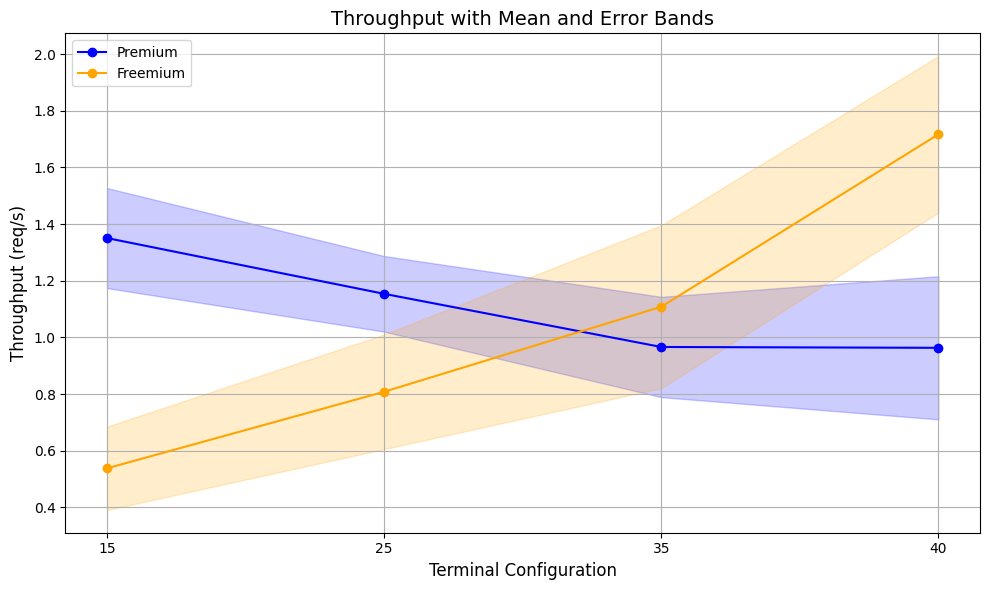

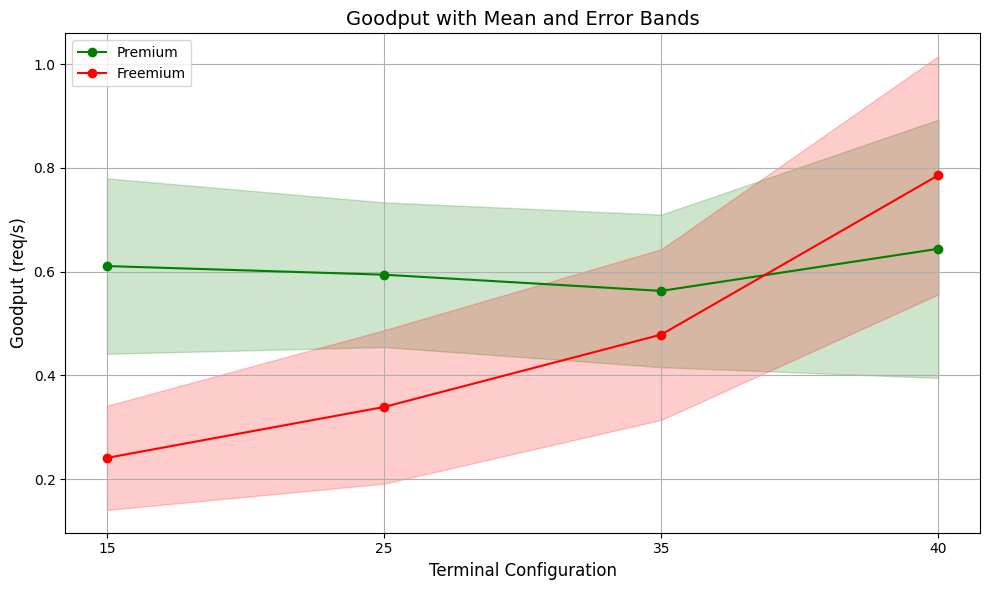

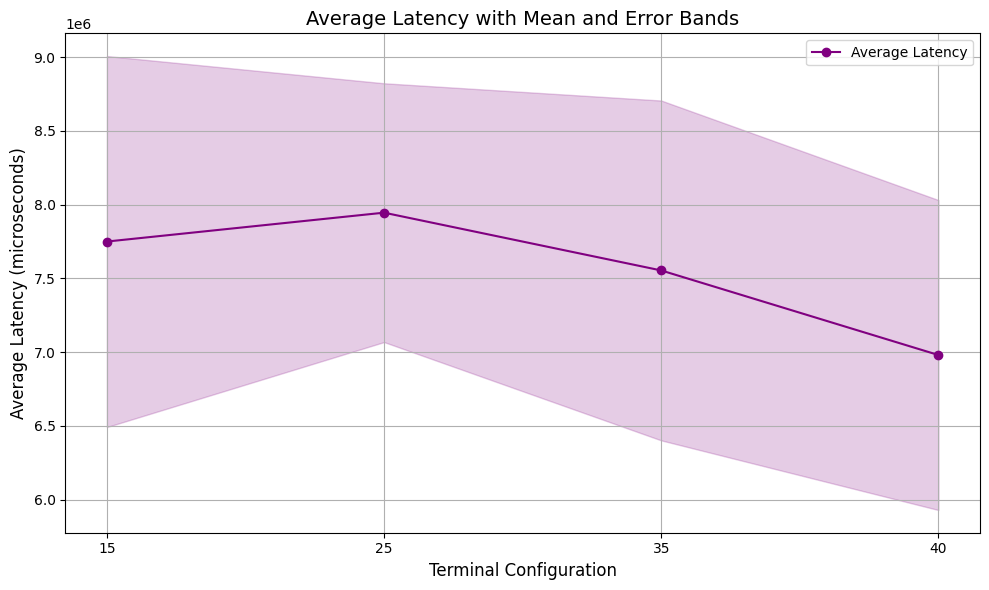

In [1]:
# Performance Analysis of Premium and Freemium Users
# This notebook visualizes **Throughput**, **Goodput**, and **Average Latency** for **Premium** and **Freemium** users, including error bands across repeated experiments.

# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load CSV Data
csv_file = 'summary_results_new.csv'  
df = pd.read_csv(csv_file)
df.head()

# Data Preprocessing
# Group the data by terminal configurations and calculate mean and standard deviation

# Create a column for terminal configuration (e.g., '15:35')
df['Terminal Config'] = df['Terminal Classes Weights'].astype(str)

# Group by terminal configuration
grouped = df.groupby('Terminal Config')

# Calculate mean and std for throughput, goodput, and avg latency
summary = grouped.agg({
    'premium_Throughput': ['mean', 'std'],
    'freemium_Throughput': ['mean', 'std'],
    'premium_Goodput': ['mean', 'std'],
    'freemium_Goodput': ['mean', 'std'],
    'Average Latency': ['mean', 'std']
})

# Flatten column names
summary.columns = ['_'.join(col).strip() for col in summary.columns.values]
summary = summary.reset_index()

summary

# Throughput Plot with Error Bands
fig, ax = plt.subplots(figsize=(10, 6))

x = summary['Terminal Config']

# Plot Premium Throughput
ax.plot(x, summary['premium_Throughput_mean'], label='Premium', color='blue', marker='o')
ax.fill_between(x,
                summary['premium_Throughput_mean'] - summary['premium_Throughput_std'],
                summary['premium_Throughput_mean'] + summary['premium_Throughput_std'],
                color='blue', alpha=0.2)

# Plot Freemium Throughput
ax.plot(x, summary['freemium_Throughput_mean'], label='Freemium', color='orange', marker='o')
ax.fill_between(x,
                summary['freemium_Throughput_mean'] - summary['freemium_Throughput_std'],
                summary['freemium_Throughput_mean'] + summary['freemium_Throughput_std'],
                color='orange', alpha=0.2)

ax.set_xlabel('Terminal Configuration', fontsize=12)
ax.set_ylabel('Throughput (req/s)', fontsize=12)
ax.set_title('Throughput with Mean and Error Bands', fontsize=14)
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

# Goodput Plot with Error Bands
fig, ax = plt.subplots(figsize=(10, 6))

# Plot Premium Goodput
ax.plot(x, summary['premium_Goodput_mean'], label='Premium', color='green', marker='o')
ax.fill_between(x,
                summary['premium_Goodput_mean'] - summary['premium_Goodput_std'],
                summary['premium_Goodput_mean'] + summary['premium_Goodput_std'],
                color='green', alpha=0.2)

# Plot Freemium Goodput
ax.plot(x, summary['freemium_Goodput_mean'], label='Freemium', color='red', marker='o')
ax.fill_between(x,
                summary['freemium_Goodput_mean'] - summary['freemium_Goodput_std'],
                summary['freemium_Goodput_mean'] + summary['freemium_Goodput_std'],
                color='red', alpha=0.2)

ax.set_xlabel('Terminal Configuration', fontsize=12)
ax.set_ylabel('Goodput (req/s)', fontsize=12)
ax.set_title('Goodput with Mean and Error Bands', fontsize=14)
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

# Average Latency Plot with Error Bands
fig, ax = plt.subplots(figsize=(10, 6))

# Plot Average Latency
ax.plot(x, summary['Average Latency_mean'], label='Average Latency', color='purple', marker='o')
ax.fill_between(x,
                summary['Average Latency_mean'] - summary['Average Latency_std'],
                summary['Average Latency_mean'] + summary['Average Latency_std'],
                color='purple', alpha=0.2)

ax.set_xlabel('Terminal Configuration', fontsize=12)
ax.set_ylabel('Average Latency (microseconds)', fontsize=12)
ax.set_title('Average Latency with Mean and Error Bands', fontsize=14)
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()
